# SocialShield: how the models are trained

**Network Security project, MPSTME.** Pravara Jain (K020), Yash Mehta (K035), Somya Soni (K063)

This notebook shows, step by step, how SocialShield learns to spot **fake accounts** and **scam messages**.
Press **Runtime > Run all**. It takes about 3 minutes and every result appears below its step.

| Step | What happens |
|---|---|
| 1 | Load the dataset |
| 2 | Look at genuine vs fake accounts |
| 3 | Turn every account into 32 numbers (features) |
| 4 | Split into training and test accounts |
| 5 | Train three models and compare them |
| 6 | See what the model learned |
| 7 | Find out what type of attacker each fake account is |
| 8 | Train the message model |
| 9 | Try your own messages |
| 10 | Honest test on real SMS messages |

## Setup
Downloads our project code and data from GitHub, so the notebook uses exactly the same code as the app.

In [1]:
import os, sys
if not os.path.exists("socialshield"):
    !git clone -q https://github.com/spy-ka-y/socialshield.git
os.chdir("socialshield")
sys.path.insert(0, "src")

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 20)
print("Ready. Project files:", sorted(os.listdir("src"))[:6], "...")

Ready. Project files: ['ai_layer.py', 'detector.py', 'evaluate.py', 'evaluate_ai.py', 'features.py', 'incidents.py'] ...


## Step 1: Load the dataset
We use the Kaggle dataset **"Fake Profile and Post Detection on Social Media"**. It has two files:
* **profiles**: one row per account (followers, account age, bio, ...), and whether it is fake
* **activities**: every post those accounts made (text, likes, shares, time, device, ...)

In [2]:
profiles = pd.read_csv("data/raw_user_profiles.csv")
activities = pd.read_csv("data/raw_user_activities.csv")
print(f"{len(profiles):,} accounts and {len(activities):,} posts")
profiles[["user_id", "username", "account_age_days", "followers_count", "following_count", "posts_count",
          "has_bio", "is_verified", "account_type", "is_fake"]].head()

5,000 accounts and 131,284 posts


,user_id,username,account_age_days,followers_count,following_count,posts_count,has_bio,is_verified,account_type,is_fake
0,b74f2b71-054b-4f53-a3af-7af090c283d3,peterkonda,211,105,80,24,False,False,active_user,False
1,ce876a7e-6760-4978-a62b-683102cef949,jhoffman600,265,5,231,25,False,False,active_user,False
2,a45c299b-37a1-4dea-922c-432d3dc28c63,official_billgates634,101,651,5,28,True,True,impersonation,True
3,4af989e7-368c-4b4b-a071-c5e9b3f19f48,hassan82,704,124,65,28,False,False,active_user,False
4,087382bb-cace-4128-82ab-f133501759fb,facts124568,58,9,18,20,False,False,bot,True


In [3]:
activities[["user_id", "timestamp", "content", "likes", "shares", "device", "content_type"]].head()

,user_id,timestamp,content,likes,shares,device,content_type
0,b74f2b71-054b-4f53-a3af-7af090c283d3,2024-09-10 16:50:00,Highlight of my day was definitely beating my ...,43,1,iPhone,active_user
1,b74f2b71-054b-4f53-a3af-7af090c283d3,2024-09-13 15:53:00,Just posted a new photo on my profile! Check i...,21,4,iPhone,active_user
2,b74f2b71-054b-4f53-a3af-7af090c283d3,2024-09-14 09:31:00,Feeling inspired after cleaning out my closet....,16,1,Android,active_user
3,b74f2b71-054b-4f53-a3af-7af090c283d3,2024-09-14 22:05:00,Finally got around to cleaning out my closet a...,16,0,iPhone,active_user
4,b74f2b71-054b-4f53-a3af-7af090c283d3,2024-09-15 18:25:00,Highlight of my day was definitely finding the...,6,1,iPhone,active_user


## Step 2: Genuine vs fake accounts
About one account in four is fake, and the fake ones come in six types of attacker.

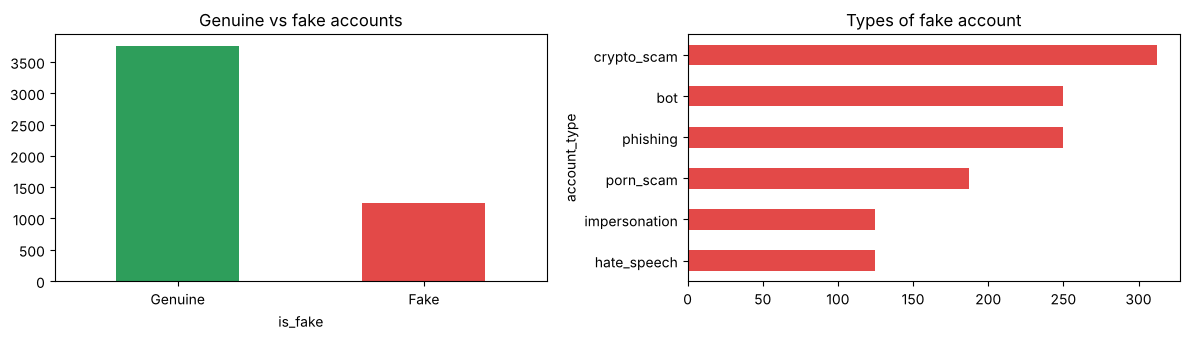

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
profiles["is_fake"].map({False: "Genuine", True: "Fake"}).value_counts().plot.bar(ax=ax[0], color=["#2e9e5b", "#e34948"], rot=0)
ax[0].set_title("Genuine vs fake accounts")
profiles.loc[profiles["is_fake"], "account_type"].value_counts().plot.barh(ax=ax[1], color="#e34948")
ax[1].set_title("Types of fake account"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Important: label leakage.** The columns `account_type` and `content_type` give the answer away directly
(for example `content_type = "phishing"`). If the model could see them it would score 100% without learning anything.
So they are **never** used as inputs, only to name the alert categories.

## Step 3: Turn every account into 32 numbers
A model cannot read a profile; it needs numbers. We describe each account with 32 **features** in three groups:
* **Profile (12):** account age, followers, following, number of posts, has a bio, has a picture, verified, ...
* **Username and email (5):** followers-to-following ratio, digits in the username, free email provider, ...
* **Behaviour (15), computed from the account's posts:** average likes and shares, share of posts with links,
  average gap between posts, posting at night, how often it repeats the same post, ...

The code is in `src/features.py`, the same file the app uses.

In [5]:
from features import build_account_table, PROFILE_FEATURES, USERNAME_FEATURES, BEHAVIOR_FEATURES
X = build_account_table(profiles, activities)
labels = profiles.set_index("user_id").loc[X.index]
y = labels["is_fake"].astype(int)          # 1 = fake, 0 = genuine
attack = labels["account_type"]
print("Feature table:", X.shape[0], "accounts x", X.shape[1], "features")
X.head(3).round(2)

Feature table: 5000 accounts x 32 features


,account_age_days,profile_completeness,followers_count,following_count,posts_count,is_private,is_verified,profile_picture,profile_banner,has_bio,...,avg_mentions,avg_chars,media_ratio,gap_mean_h,gap_std_h,hour_std,night_ratio,uniq_devices,uniq_countries,repeat_ratio
user_id,,,,,,,,,,,,,,,,,,,,,
b74f2b71-054b-4f53-a3af-7af090c283d3,211.0,0.67,105.0,80.0,24.0,0.0,0.0,1.0,1.0,0.0,...,0.0,64.29,0.50,25.01,22.69,4.30,0.00,3,1,0.00
ce876a7e-6760-4978-a62b-683102cef949,265.0,0.69,5.0,231.0,25.0,1.0,0.0,1.0,0.0,0.0,...,0.0,69.44,0.56,37.09,37.65,3.59,0.00,1,2,0.08
a45c299b-37a1-4dea-922c-432d3dc28c63,101.0,0.82,651.0,5.0,28.0,0.0,1.0,1.0,0.0,1.0,...,0.0,68.43,0.43,76.23,85.07,7.23,0.25,2,4,0.68


**How different do fake and genuine accounts look?** The typical (median) value of some features for each group:

In [6]:
cols = ["account_age_days", "followers_count", "following_count", "follower_following_ratio",
        "avg_likes", "repeat_ratio", "night_ratio", "url_ratio"]
compare = pd.DataFrame({"Typical genuine account": X[y == 0][cols].median(),
                        "Typical fake account": X[y == 1][cols].median()}).round(2)
compare

,Typical genuine account,Typical fake account
account_age_days,874.00,39.00
followers_count,103.00,5.00
following_count,58.00,7.00
follower_following_ratio,1.40,0.83
avg_likes,31.73,3.95
repeat_ratio,0.05,0.03
night_ratio,0.00,0.23
url_ratio,0.00,0.00


## Step 4: Split into training and test accounts
The model learns from **80%** of the accounts (4,000) and is then tested on the other **20%** (1,000)
that it has never seen. The split keeps the same mix of attacker types in both parts.

In [7]:
from sklearn.model_selection import train_test_split
tr_idx, te_idx = train_test_split(np.asarray(X.index, dtype=object), test_size=0.2, random_state=42, stratify=attack)
Xtr, Xte, ytr, yte = X.loc[tr_idx], X.loc[te_idx], y.loc[tr_idx], y.loc[te_idx]
print(f"Training: {len(Xtr):,} accounts ({ytr.sum()} fake)   Test: {len(Xte):,} accounts ({yte.sum()} fake)")

Training: 4,000 accounts (999 fake)   Test: 1,000 accounts (250 fake)


## Step 5: Train three models and compare them
* **Logistic Regression:** draws one straight boundary between genuine and fake.
* **SVM (RBF kernel):** can draw a curved boundary.
* **Random Forest:** 300 decision trees, each asking yes/no questions such as
  *"Is the account younger than 30 days?"*, then voting.

We use **Random Forest** in the app because it also tells us *which* features drove the decision, so every alert can be explained.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced", random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
}
rows = []
for name, m in models.items():
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    rows.append({"Model": name, "Accuracy": accuracy_score(yte, p), "Precision": precision_score(yte, p),
                 "Recall": recall_score(yte, p), "F1-score": f1_score(yte, p)})
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,1.0,1.0,1.0,1.0
SVM (RBF),1.0,1.0,1.0,1.0
Random Forest,1.0,1.0,1.0,1.0


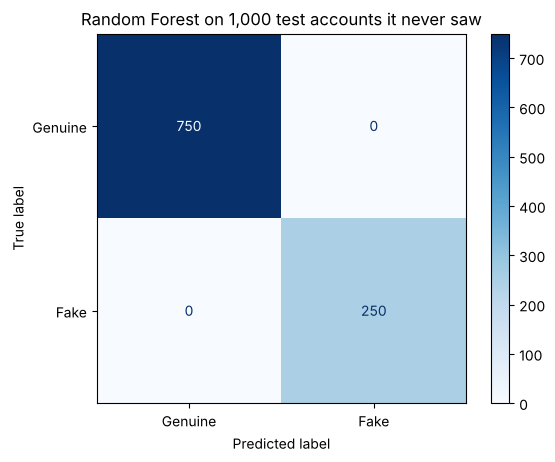

In [9]:
rf = models["Random Forest"]
ConfusionMatrixDisplay(confusion_matrix(yte, rf.predict(Xte)), display_labels=["Genuine", "Fake"]).plot(cmap="Blues")
plt.title("Random Forest on 1,000 test accounts it never saw"); plt.show()

**Why 100%?** Not because the model is magic: the dataset is **synthetic** (computer-generated), so fake and genuine
accounts barely overlap. The chart below shows it for account age. Real platforms are much harder,
which is why Step 10 and our report test the system on real data.

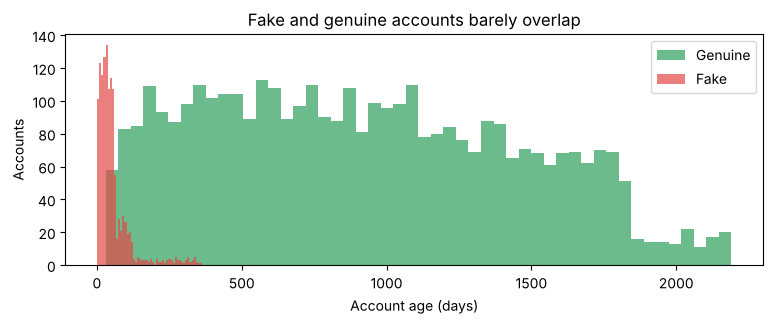

In [10]:
plt.figure(figsize=(9, 3))
plt.hist(X[y == 0]["account_age_days"], bins=50, alpha=0.7, label="Genuine", color="#2e9e5b")
plt.hist(X[y == 1]["account_age_days"], bins=50, alpha=0.7, label="Fake", color="#e34948")
plt.xlabel("Account age (days)"); plt.ylabel("Accounts"); plt.legend(); plt.title("Fake and genuine accounts barely overlap")
plt.show()

## Step 6: What did the model learn?
Random Forest measures how much each feature helped it decide. These are the clues it relies on most.

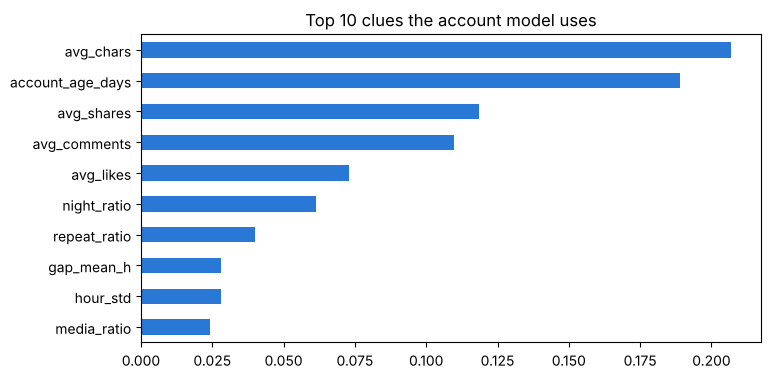

In [11]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(8, 4), color="#2a78d6"); plt.title("Top 10 clues the account model uses"); plt.show()

**Explaining one decision.** For a fake test account, compare it with a typical genuine account on the top clues:

In [12]:
one = Xte[yte == 1].iloc[0]
top = imp.index[::-1][:5]
pd.DataFrame({"This account": one[top].round(2), "Typical genuine account": X[y == 0][top].median().round(2)})

,This account,Typical genuine account
avg_chars,107.77,66.23
account_age_days,32.00,874.00
avg_shares,0.02,2.24
avg_comments,0.91,6.18
avg_likes,3.44,31.73


## Step 7: What type of attacker is it?
A second Random Forest, trained **only on fake accounts**, names the attacker type: spam bot, phisher,
money scammer, adult-content scammer, impersonator or misinformation spreader.

In [13]:
from sklearn.metrics import classification_report
fake_tr, fake_te = tr_idx[ytr.values == 1], te_idx[yte.values == 1]
atk = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X.loc[fake_tr], attack.loc[fake_tr])
print(classification_report(attack.loc[fake_te], atk.predict(X.loc[fake_te]), digits=3))

               precision    recall  f1-score   support

          bot      1.000     1.000     1.000        50
  crypto_scam      1.000     1.000     1.000        63
  hate_speech      1.000     1.000     1.000        25
impersonation      1.000     1.000     1.000        25
     phishing      1.000     1.000     1.000        50
    porn_scam      1.000     1.000     1.000        37

     accuracy                          1.000       250
    macro avg      1.000     1.000     1.000       250
 weighted avg      1.000     1.000     1.000       250



## Step 8: Train the message model
Now the posts themselves. Every post gets one of seven verdicts: Safe, Phishing, Money Scam, Spam,
Misinformation, Impersonation or Adult Scam.

1. **TF-IDF** turns text into numbers: each word (and short piece of a word) gets a score that is high when
   it appears in this message but is rare overall. So *"verify"*, *"OTP"* or *"send money"* stand out.
2. **Logistic Regression** learns which words go with which verdict.

We split **by account** (80% / 20%), so no account's posts are in both the training and test sets.

In [14]:
from features import alert_label
from sklearn.model_selection import GroupShuffleSplit
from train_post_model import vectorizer

activities["alert"] = activities["content_type"].map(alert_label)
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(activities, groups=activities["user_id"]))
train, test = activities.iloc[tr], activities.iloc[te]
train_u = train.drop_duplicates(["content", "alert"])      # the same post repeated many times counts once
print(f"Training on {len(train_u):,} unique posts, testing on {len(test):,} posts from unseen accounts")

msg_model = make_pipeline(vectorizer(), LogisticRegression(max_iter=3000, class_weight="balanced", C=5))
msg_model.fit(train_u["content"], train_u["alert"])
print(classification_report(test["alert"], msg_model.predict(test["content"]), digits=3))

Training on 12,003 unique posts, testing on 26,519 posts from unseen accounts


                precision    recall  f1-score   support

    Adult Scam      1.000     1.000     1.000       723
 Impersonation      1.000     1.000     1.000       439
Misinformation      1.000     1.000     1.000       424
    Money Scam      1.000     1.000     1.000      2083
      Phishing      1.000     1.000     1.000       438
          Safe      1.000     1.000     1.000     20855
          Spam      1.000     1.000     1.000      1557

      accuracy                          1.000     26519
     macro avg      1.000     1.000     1.000     26519
  weighted avg      1.000     1.000     1.000     26519



**What words did it learn?** The words that push hardest towards each scam type:

In [15]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # skip filler words like "my", "with"
words = dict(msg_model.steps[0][1].transformer_list)["words"]
names, n = words.get_feature_names_out(), len(words.vocabulary_)
clf = msg_model.steps[-1][1]
for k, cls in enumerate(clf.classes_):
    if cls == "Safe":
        continue
    top_w = [names[i] for i in np.argsort(clf.coef_[k][:n])[::-1]
             if "token" not in names[i] and not all(w in ENGLISH_STOP_WORDS or len(w) < 3 for w in names[i].split())][:8]
    print(f"{cls:15s} {', '.join(top_w)}")

Adult Scam      page, tonight, my private, private page, private, check my, link, content
Impersonation   my exclusive, interview, exclusive interview, exclusive, interview with, official, movie, grateful
Misinformation  research, rise, responsible for, responsible, the rise, are responsible, fact, research it
Money Scam      insider, strategy, insider info, info, secret, learn, system link, trading
Phishing        account, congratulations, congratulations you, selected for, selected, been selected, re authenticate, terms of
Spam            in just, news, pounds, lose, weight, this investment, opportunity is, investment opportunity


## Step 9: Try your own messages
In the app, the ML model is combined with **37 hand-written scam rules**, a **link checker** (392,151 real phishing
domains) and a step that undoes disguised text. Change the messages below and run the cell again.

In [16]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({"model": msg_model, "classes": list(clf.classes_)}, "models/post_model.joblib")
from detector import MessageDetector
det = MessageDetector()

messages = [
    "Your SBI KYC has expired. Update now or your account will be blocked: sbi-kyc-update.xyz",
    "Hi it's Rahul, this is my new number. Lost my phone, can you pay 5000 for me urgently?",
    "Hi, this is your HOD. Buy 3 Google Play gift cards of Rs 2000 each urgently, I will reimburse you.",
    "Congrats on the new job! Let's celebrate this weekend",
]
for m in messages:
    v = det.analyze(m)
    print(f"{v.label:14s} risk {v.risk:4.0%} | ML alone: {v.ml_label:12s} | rules: {[h['id'] for h in v.rule_hits]}")
    print("   ", m, "\n")

Phishing       risk 100% | ML alone: Phishing     | rules: ['PH-01', 'PH-03', 'PH-06', 'GN-02', 'LK-02', 'LK-05', 'LK-07']
    Your SBI KYC has expired. Update now or your account will be blocked: sbi-kyc-update.xyz 

Money Scam     risk  67% | ML alone: Safe         | rules: ['MS-01', 'IM-02', 'GN-01']
    Hi it's Rahul, this is my new number. Lost my phone, can you pay 5000 for me urgently? 

Impersonation  risk  94% | ML alone: Safe         | rules: ['IM-03', 'IM-04', 'GN-01']
    Hi, this is your HOD. Buy 3 Google Play gift cards of Rs 2000 each urgently, I will reimburse you. 

Safe           risk   4% | ML alone: Safe         | rules: []
    Congrats on the new job! Let's celebrate this weekend 



## Step 10: Honest test on real SMS messages
Everything above used synthetic data. Here the system meets **5,574 real text messages**
(UCI SMS Spam Collection, 747 spam) that it was never trained on.

In [17]:
sms = pd.read_csv("data/external/sms.tsv", sep="\t", header=None, names=["label", "text"], quoting=3)
is_spam = (sms["label"] == "spam").values
flagged = np.array([v.label != "Safe" for v in det.analyze_many(sms["text"].tolist())])
print(f"Real spam caught:            {flagged[is_spam].mean():.0%}")
print(f"Genuine messages flagged:    {flagged[~is_spam].mean():.1%}")

Real spam caught:            23%
Genuine messages flagged:    0.3%


Low detection, but almost no false alarms: the model learned the *style* of the synthetic dataset.
What happens if we train the **same design** on real messages instead?

In [18]:
s_tr, s_te = train_test_split(sms, test_size=0.2, stratify=sms["label"], random_state=42)
real_model = make_pipeline(vectorizer(), LogisticRegression(max_iter=3000, class_weight="balanced", C=5))
real_model.fit(s_tr["text"], s_tr["label"])
p = real_model.predict(s_te["text"])
print(f"Retrained on real SMS -> spam caught: {(p[s_te['label'] == 'spam'] == 'spam').mean():.0%}, "
      f"false alarms: {(p[s_te['label'] == 'ham'] == 'spam').mean():.1%}")

Retrained on real SMS -> spam caught: 95%, false alarms: 0.3%


## What this shows (what to say in the viva)
1. **Training:** 32 features per account, Random Forest, 80/20 split; TF-IDF + Logistic Regression for messages.
2. **Results on the dataset:** 100%, but because the dataset is synthetic, not because the problem is easy.
3. **On real messages:** the same detector catches far less. Retrained on real data, the same design catches about 95%.
4. **Lesson:** a model only knows the data it learned from. That is why SocialShield adds rules, a link checker
   and evasion tests, and why we report where it fails.